In [ ]:
!pip install -q xgboost

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import time
import sklearn
import xgboost

from google.colab import drive, files

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import LabelEncoder, label_binarize
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils.class_weight import compute_sample_weight

from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc
)

print("Scikit-learn version:", sklearn.__version__)
print("XGBoost version:", xgboost.__version__)

Scikit-learn version: 1.6.1
XGBoost version: 3.4.1


In [ ]:
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
DATA_PATH = (
    "/content/drive/MyDrive/Football_ML_Project/"
    "FIFA_Male_Players_2015_2023.csv"
)


**Load DataSet**

In [ ]:
df = pd.read_csv(DATA_PATH, low_memory=False)

print("Dataset shape:", df.shape)
print("Number of records:", df.shape[0])
print("Number of columns:", df.shape[1])

df.head()


Dataset shape: (161583, 110)
Number of records: 161583
Number of columns: 110


,player_id,player_url,fifa_version,fifa_update,fifa_update_date,short_name,long_name,player_positions,overall,potential,...,cdm,rdm,rwb,lb,lcb,cb,rcb,rb,gk,player_face_url
0,158023,/player/158023/lionel-messi/150002,15,2,2014-09-18,L. Messi,Lionel Andrés Messi Cuccittini,CF,93,95,...,62+3,62+3,62+3,54+3,45+3,45+3,45+3,54+3,15+3,https://cdn.sofifa.net/players/158/023/15_120.png
1,20801,/player/20801/c-ronaldo-dos-santos-aveiro/150002,15,2,2014-09-18,Cristiano Ronaldo,Cristiano Ronaldo dos Santos Aveiro,"LW, LM",92,92,...,63+3,63+3,63+3,57+3,52+3,52+3,52+3,57+3,16+3,https://cdn.sofifa.net/players/020/801/15_120.png
2,9014,/player/9014/arjen-robben/150002,15,2,2014-09-18,A. Robben,Arjen Robben,"RM, LM, RW",90,90,...,64+3,64+3,64+3,55+3,46+3,46+3,46+3,55+3,14+3,https://cdn.sofifa.net/players/009/014/15_120.png
3,41236,/player/41236/zlatan-ibrahimovic/150002,15,2,2014-09-18,Z. Ibrahimović,Zlatan Ibrahimović,ST,90,90,...,65+3,65+3,61+3,56+3,55+3,55+3,55+3,56+3,17+3,https://cdn.sofifa.net/players/041/236/15_120.png
4,167495,/player/167495/manuel-neuer/150002,15,2,2014-09-18,M. Neuer,Manuel Peter Neuer,GK,90,90,...,40+3,40+3,36+3,36+3,38+3,38+3,38+3,36+3,87+3,https://cdn.sofifa.net/players/167/495/15_120.png


**Inspect DataSet**

In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 161583 entries, 0 to 161582
Columns: 110 entries, player_id to player_face_url
dtypes: float64(18), int64(45), object(47)
memory usage: 135.6+ MB


**Check Missing Values**

In [ ]:
missing_values = (
    df.isnull()
      .sum()
      .sort_values(ascending=False)
)

missing_values[missing_values > 0].head(20)

,0
nation_team_id,152267
nation_position,152267
nation_jersey_number,152267
club_loaned_from,152045
player_tags,148920
goalkeeping_speed,143614
player_traits,88433
release_clause_eur,57961
mentality_composure,32861
pace,17969


**Check Duplicate Rows**

In [ ]:
print("Duplicate rows:", df.duplicated().sum())
print("Unique players:", df["player_id"].nunique())

Duplicate rows: 0
Unique players: 49699


**Create Target Variable**

In [ ]:
df["primary_position"] = (
    df["player_positions"]
    .str.split(",")
    .str[0]
    .str.strip()
)

POSITION_MAPPING = {
    # Goalkeeper
    "GK": "Goalkeeper",

    # Defenders
    "CB": "Defender",
    "LB": "Defender",
    "RB": "Defender",
    "LWB": "Defender",
    "RWB": "Defender",

    # Midfielders
    "CDM": "Midfielder",
    "CM": "Midfielder",
    "CAM": "Midfielder",
    "LM": "Midfielder",
    "RM": "Midfielder",

    # Forwards
    "ST": "Forward",
    "CF": "Forward",
    "LW": "Forward",
    "RW": "Forward"
}

df["position_group"] = df["primary_position"].map(POSITION_MAPPING)

df = df.dropna(
    subset=["position_group", "player_id"]
).copy()

print(df["position_group"].value_counts())

position_group
Midfielder    59843
Defender      52729
Forward       31041
Goalkeeper    17970
Name: count, dtype: int64


**Visualize Target Distribution**

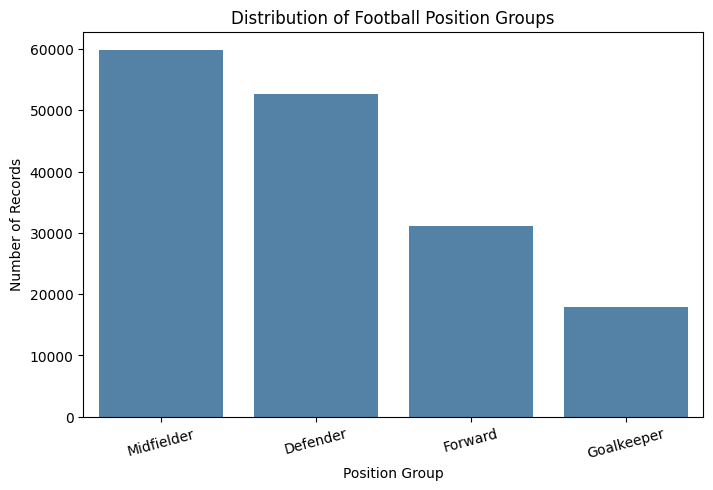

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="position_group",
    order=df["position_group"].value_counts().index,
    color="steelblue"
)

plt.title("Distribution of Football Position Groups")
plt.xlabel("Position Group")
plt.ylabel("Number of Records")
plt.xticks(rotation=15)
plt.show()

**Select 41 Input Features**

In [ ]:
FEATURES = [
    # Personal and general attributes
    "age",
    "height_cm",
    "weight_kg",
    "weak_foot",
    "skill_moves",
    "international_reputation",

    # Attacking
    "attacking_crossing",
    "attacking_finishing",
    "attacking_heading_accuracy",
    "attacking_short_passing",
    "attacking_volleys",

    # Skills
    "skill_dribbling",
    "skill_curve",
    "skill_fk_accuracy",
    "skill_long_passing",
    "skill_ball_control",

    # Movement
    "movement_acceleration",
    "movement_sprint_speed",
    "movement_agility",
    "movement_reactions",
    "movement_balance",

    # Power
    "power_shot_power",
    "power_jumping",
    "power_stamina",
    "power_strength",
    "power_long_shots",

    # Mentality
    "mentality_aggression",
    "mentality_interceptions",
    "mentality_positioning",
    "mentality_vision",
    "mentality_penalties",
    "mentality_composure",

    # Defending
    "defending_marking_awareness",
    "defending_standing_tackle",
    "defending_sliding_tackle",

    # Goalkeeping
    "goalkeeping_diving",
    "goalkeeping_handling",
    "goalkeeping_kicking",
    "goalkeeping_positioning",
    "goalkeeping_reflexes",
    "goalkeeping_speed"
]

print("Selected input features:", len(FEATURES))

assert len(FEATURES) >= 35, "The feature requirement is not satisfied."

Selected input features: 41


**Prepare Input & Target Data**

In [ ]:
X = df[FEATURES].apply(
    pd.to_numeric,
    errors="coerce"
)

target_encoder = LabelEncoder()
y = target_encoder.fit_transform(df["position_group"])

groups = df["player_id"].astype(str)

print("Input shape:", X.shape)
print("Target shape:", y.shape)
print("Target classes:", target_encoder.classes_)
print("Missing feature cells:", X.isnull().sum().sum())

Input shape: (161583, 41)
Target shape: (161583,)
Target classes: ['Defender' 'Forward' 'Goalkeeper' 'Midfielder']
Missing feature cells: 176475


**Create 80/20 group Split**

In [ ]:
splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_index, test_index = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_index]
X_test = X.iloc[test_index]

y_train = y[train_index]
y_test = y[test_index]

groups_train = groups.iloc[train_index]
groups_test = groups.iloc[test_index]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Training percentage:", len(X_train) / len(X) * 100)
print("Testing percentage:", len(X_test) / len(X) * 100)

Training records: 129267
Testing records: 32316
Training percentage: 80.00037132619148
Testing percentage: 19.999628673808505


Verify that no two players exist in both sets

In [ ]:
shared_players = set(groups_train).intersection(set(groups_test))

print("Players appearing in both sets:", len(shared_players))

assert len(shared_players) == 0, "Player leakage detected!"

Players appearing in both sets: 0


**Define RandomForest & XGBoost**

In [ ]:
random_forest_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="median",
            add_indicator=True
        )
    ),
    (
        "model",
        RandomForestClassifier(
            n_estimators=250,
            max_depth=20,
            min_samples_leaf=2,
            max_features="sqrt",
            class_weight="balanced_subsample",
            random_state=42,
            n_jobs=-1
        )
    )
])

xgboost_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="median",
            add_indicator=True
        )
    ),
    (
        "model",
        XGBClassifier(
            objective="multi:softprob",
            num_class=len(target_encoder.classes_),
            n_estimators=300,
            learning_rate=0.08,
            max_depth=7,
            min_child_weight=3,
            subsample=0.80,
            colsample_bytree=0.80,
            reg_alpha=0.10,
            reg_lambda=1.50,
            tree_method="hist",
            eval_metric="mlogloss",
            random_state=42,
            n_jobs=-1
        )
    )
])

models = {
    "Random Forest": random_forest_pipeline,
    "XGBoost": xgboost_pipeline
}

**Train Both Models**

In [ ]:
training_times = {}

# Random Forest
start_time = time.time()

models["Random Forest"].fit(
    X_train,
    y_train
)

training_times["Random Forest"] = time.time() - start_time

print(
    "Random Forest training time:",
    round(training_times["Random Forest"], 2),
    "seconds"
)

Random Forest training time: 105.97 seconds


In [ ]:
xgb_sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

start_time = time.time()

models["XGBoost"].fit(
    X_train,
    y_train,
    model__sample_weight=xgb_sample_weights
)

training_times["XGBoost"] = time.time() - start_time

print(
    "XGBoost training time:",
    round(training_times["XGBoost"], 2),
    "seconds"
)

XGBoost training time: 33.08 seconds


**Compare Required Metircs**

In [ ]:
results = []
predictions = {}
probabilities = {}

for model_name, model in models.items():

    y_pred = model.predict(X_test)
    y_probability = model.predict_proba(X_test)

    predictions[model_name] = y_pred
    probabilities[model_name] = y_probability

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision Macro": precision_score(
            y_test,
            y_pred,
            average="macro",
            zero_division=0
        ),
        "Recall Macro": recall_score(
            y_test,
            y_pred,
            average="macro",
            zero_division=0
        ),
        "F1 Macro": f1_score(
            y_test,
            y_pred,
            average="macro",
            zero_division=0
        ),
        "ROC-AUC Macro OVR": roc_auc_score(
            y_test,
            y_probability,
            multi_class="ovr",
            average="macro"
        ),
        "Training Time": training_times[model_name]
    })

comparison = (
    pd.DataFrame(results)
    .set_index("Model")
    .sort_values("F1 Macro", ascending=False)
)

display(comparison.style.format("{:.4f}"))

,Accuracy,Precision Macro,Recall Macro,F1 Macro,ROC-AUC Macro OVR,Training Time
Model,,,,,,
XGBoost,0.9027,0.9122,0.9161,0.9140,0.9852,33.0772
Random Forest,0.9001,0.9143,0.9096,0.9118,0.9839,105.9712


**Display Detailed classification report**

In [ ]:
for model_name, y_pred in predictions.items():

    print("\n", "=" * 60)
    print(model_name)
    print("=" * 60)

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=target_encoder.classes_,
            digits=4,
            zero_division=0
        )
    )


Random Forest
              precision    recall  f1-score   support

    Defender     0.9332    0.9460    0.9396     10637
     Forward     0.8639    0.8199    0.8414      6303
  Goalkeeper     1.0000    1.0000    1.0000      3463
  Midfielder     0.8599    0.8726    0.8662     11913

    accuracy                         0.9001     32316
   macro avg     0.9143    0.9096    0.9118     32316
weighted avg     0.8999    0.9001    0.8999     32316


XGBoost
              precision    recall  f1-score   support

    Defender     0.9389    0.9530    0.9459     10637
     Forward     0.8287    0.8580    0.8431      6303
  Goalkeeper     0.9997    1.0000    0.9999      3463
  Midfielder     0.8817    0.8533    0.8672     11913

    accuracy                         0.9027     32316
   macro avg     0.9122    0.9161    0.9140     32316
weighted avg     0.9028    0.9027    0.9026     32316



**Check For Overfitting**

In [ ]:
overfitting_results = []

for model_name, model in models.items():

    train_prediction = model.predict(X_train)
    test_prediction = predictions[model_name]

    train_accuracy = accuracy_score(
        y_train,
        train_prediction
    )

    test_accuracy = accuracy_score(
        y_test,
        test_prediction
    )

    train_f1 = f1_score(
        y_train,
        train_prediction,
        average="macro"
    )

    test_f1 = f1_score(
        y_test,
        test_prediction,
        average="macro"
    )

    overfitting_results.append({
        "Model": model_name,
        "Train Accuracy": train_accuracy,
        "Test Accuracy": test_accuracy,
        "Accuracy Gap": train_accuracy - test_accuracy,
        "Train F1 Macro": train_f1,
        "Test F1 Macro": test_f1,
        "F1 Gap": train_f1 - test_f1
    })

overfitting_table = (
    pd.DataFrame(overfitting_results)
    .set_index("Model")
)

display(overfitting_table.style.format("{:.4f}"))

,Train Accuracy,Test Accuracy,Accuracy Gap,Train F1 Macro,Test F1 Macro,F1 Gap
Model,,,,,,
Random Forest,0.9899,0.9001,0.0897,0.9911,0.9118,0.0793
XGBoost,0.9569,0.9027,0.0541,0.9618,0.9140,0.0478


**Automatic Warning**

In [ ]:
for model_name, row in overfitting_table.iterrows():

    if row["Accuracy Gap"] > 0.05 or row["F1 Gap"] > 0.05:
        print(model_name, ": Possible overfitting—review model complexity.")
    else:
        print(model_name, ": No strong overfitting signal in this split.")

Random Forest : Possible overfitting—review model complexity.
XGBoost : Possible overfitting—review model complexity.


**Generate Confusion Metrics**

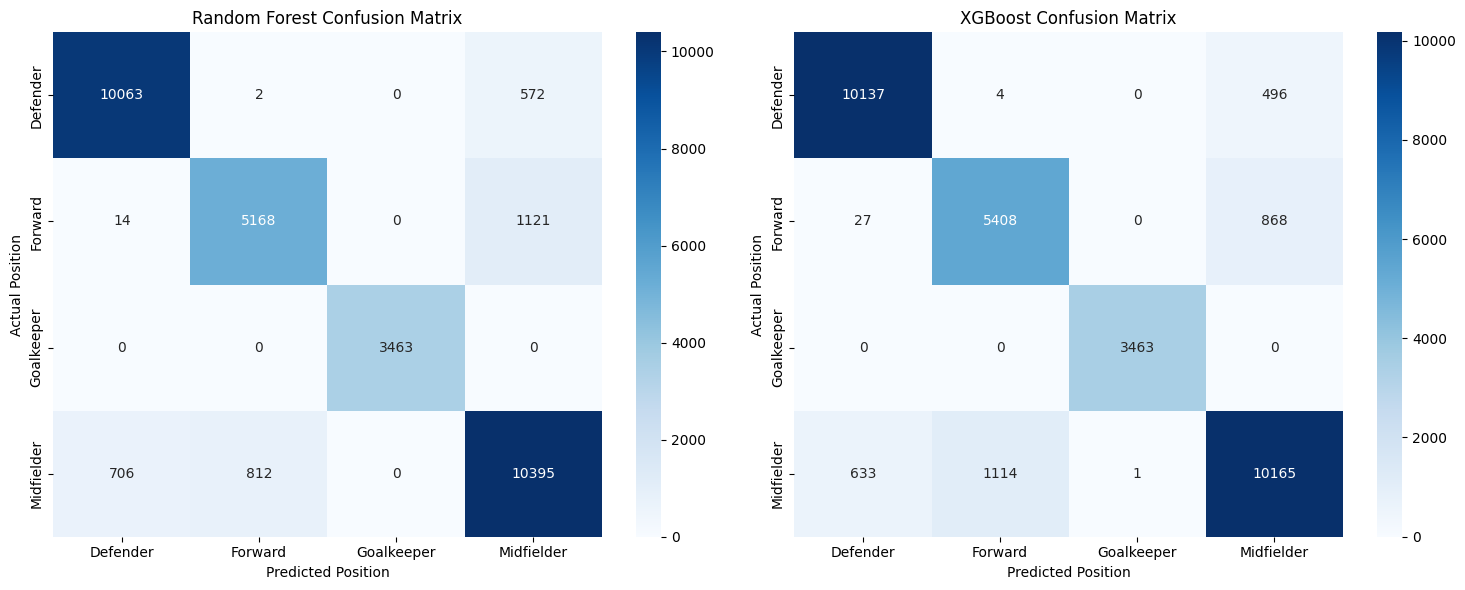

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for axis, (model_name, y_pred) in zip(
    axes,
    predictions.items()
):

    matrix = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=target_encoder.classes_,
        yticklabels=target_encoder.classes_,
        ax=axis
    )

    axis.set_title(f"{model_name} Confusion Matrix")
    axis.set_xlabel("Predicted Position")
    axis.set_ylabel("Actual Position")

plt.tight_layout()
plt.show()

**Plot ROC Curves**

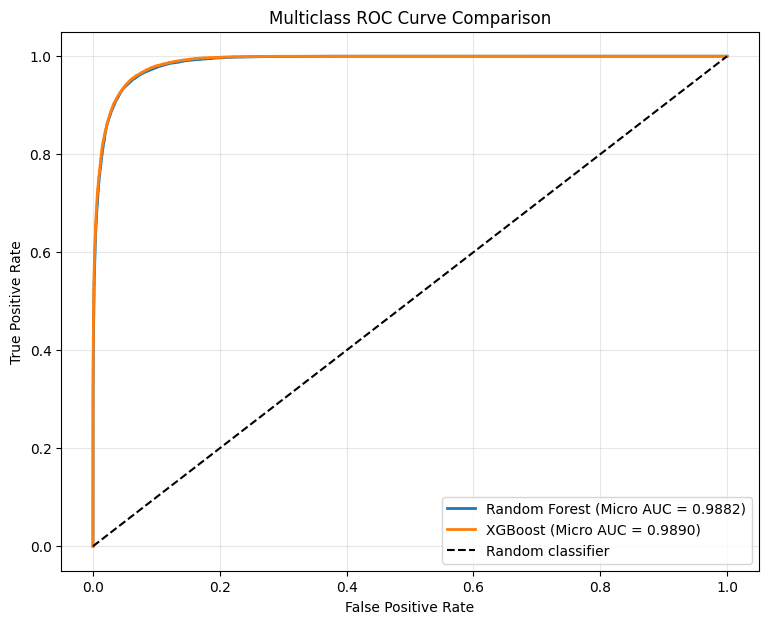

In [ ]:
number_of_classes = len(target_encoder.classes_)

y_test_binary = label_binarize(
    y_test,
    classes=np.arange(number_of_classes)
)

plt.figure(figsize=(9, 7))

for model_name, y_probability in probabilities.items():

    fpr, tpr, _ = roc_curve(
        y_test_binary.ravel(),
        y_probability.ravel()
    )

    micro_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{model_name} (Micro AUC = {micro_auc:.4f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="black",
    label="Random classifier"
)

plt.title("Multiclass ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Select Best Model**

In [ ]:
best_model_name = comparison["F1 Macro"].idxmax()
best_pipeline = models[best_model_name]

print("Selected model:", best_model_name)
print(
    "Test Macro F1:",
    comparison.loc[best_model_name, "F1 Macro"]
)

Selected model: XGBoost
Test Macro F1: 0.9140181776947043


**Export Model as PKL**

In [ ]:
MODEL_PATH = (
    "/content/drive/MyDrive/Football_ML_Project/"
    "football_position_classifier.pkl"
)

model_bundle = {
    "pipeline": best_pipeline,
    "feature_columns": FEATURES,
    "target_encoder": target_encoder,
    "position_mapping": POSITION_MAPPING,
    "model_name": best_model_name,
    "sklearn_version": sklearn.__version__,
    "xgboost_version": xgboost.__version__,
    "dataset_source": (
        "https://www.kaggle.com/datasets/"
        "stefanoleone992/fifa-23-complete-player-dataset"
    )
}

joblib.dump(model_bundle, MODEL_PATH)

print("Model saved successfully:")
print(MODEL_PATH)

Model saved successfully:
/content/drive/MyDrive/Football_ML_Project/football_position_classifier.pkl


In [ ]:
files.download(MODEL_PATH)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Test Saved Model**

In [ ]:
loaded_bundle = joblib.load(MODEL_PATH)

loaded_pipeline = loaded_bundle["pipeline"]
loaded_encoder = loaded_bundle["target_encoder"]
loaded_features = loaded_bundle["feature_columns"]

sample_player = X_test.iloc[[0]][loaded_features]

predicted_code = loaded_pipeline.predict(sample_player)[0]
predicted_position = loaded_encoder.inverse_transform(
    [predicted_code]
)[0]

actual_position = loaded_encoder.inverse_transform(
    [y_test[0]]
)[0]

print("Predicted position:", predicted_position)
print("Actual position:", actual_position)

Predicted position: Midfielder
Actual position: Midfielder
